In [3]:

import pandas as pd

# IBM SpaceX capstone launch dataset
url = (
    "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/"
    "IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_1.csv"
)

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Number of launches:", len(df))
print("Columns:", df.columns.tolist())

display(df.head())


Dataset loaded successfully!
Number of launches: 90
Columns: ['FlightNumber', 'Date', 'BoosterVersion', 'PayloadMass', 'Orbit', 'LaunchSite', 'Outcome', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial', 'Longitude', 'Latitude']


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857


In [4]:

# Save the SpaceX dataset as a CSV file
df.to_csv("SpaceX_Launch_Data.csv", index=False)

print("SpaceX dataset saved successfully!")
print("Total records:", len(df))


SpaceX dataset saved successfully!
Total records: 90


In [5]:

# Check the dataset for missing values
print("Dataset shape:", df.shape)

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nColumn names:")
print(df.columns.tolist())

print("\nLanding outcomes:")
if "Outcome" in df.columns:
    print(df["Outcome"].value_counts(dropna=False))
else:
    print("Outcome column not found")



Dataset shape: (90, 17)

Missing values in each column:
FlightNumber       0
Date               0
BoosterVersion     0
PayloadMass        0
Orbit              0
LaunchSite         0
Outcome            0
Flights            0
GridFins           0
Reused             0
Legs               0
LandingPad        26
Block              0
ReusedCount        0
Serial             0
Longitude          0
Latitude           0
dtype: int64

Column names:
['FlightNumber', 'Date', 'BoosterVersion', 'PayloadMass', 'Orbit', 'LaunchSite', 'Outcome', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial', 'Longitude', 'Latitude']

Landing outcomes:
Outcome
True ASDS      41
None None      19
True RTLS      14
False ASDS      6
True Ocean      5
False Ocean     2
None ASDS       2
False RTLS      1
Name: count, dtype: int64


In [6]:

# Create the landing success classification
# 1 = successful recovered landing
# 0 = unsuccessful or non-recovered outcome

successful_outcomes = ["True ASDS", "True RTLS"]

df["Class"] = df["Outcome"].apply(
    lambda outcome: 1 if outcome in successful_outcomes else 0
)

# Calculate landing success statistics
print("Landing classification:")
print(df["Class"].value_counts())

print("\nLanding success rate:")
print(round(df["Class"].mean() * 100, 2), "%")

# Save the prepared dataset
df.to_csv("SpaceX_Cleaned_Data.csv", index=False)

print("\nCleaned dataset saved successfully!")


Landing classification:
Class
1    55
0    35
Name: count, dtype: int64

Landing success rate:
61.11 %

Cleaned dataset saved successfully!


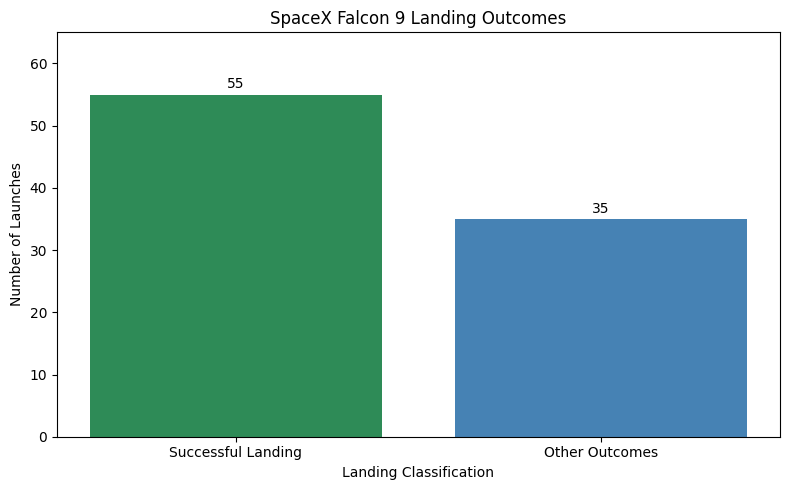

In [7]:

import matplotlib.pyplot as plt

# Count landing outcomes
landing_counts = df["Class"].value_counts().reindex(
    [1, 0], fill_value=0
)

# Create bar chart
plt.figure(figsize=(8, 5))

bars = plt.bar(
    ["Successful Landing", "Other Outcomes"],
    landing_counts.values,
    color=["seagreen", "steelblue"]
)

plt.title("SpaceX Falcon 9 Landing Outcomes")
plt.xlabel("Landing Classification")
plt.ylabel("Number of Launches")

# Display numbers above bars
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        str(int(bar.get_height())),
        ha="center"
    )

plt.ylim(0, max(landing_counts.values) + 10)
plt.tight_layout()

# Save chart
plt.savefig("SpaceX_Landing_Outcomes.png", dpi=300)

plt.show()


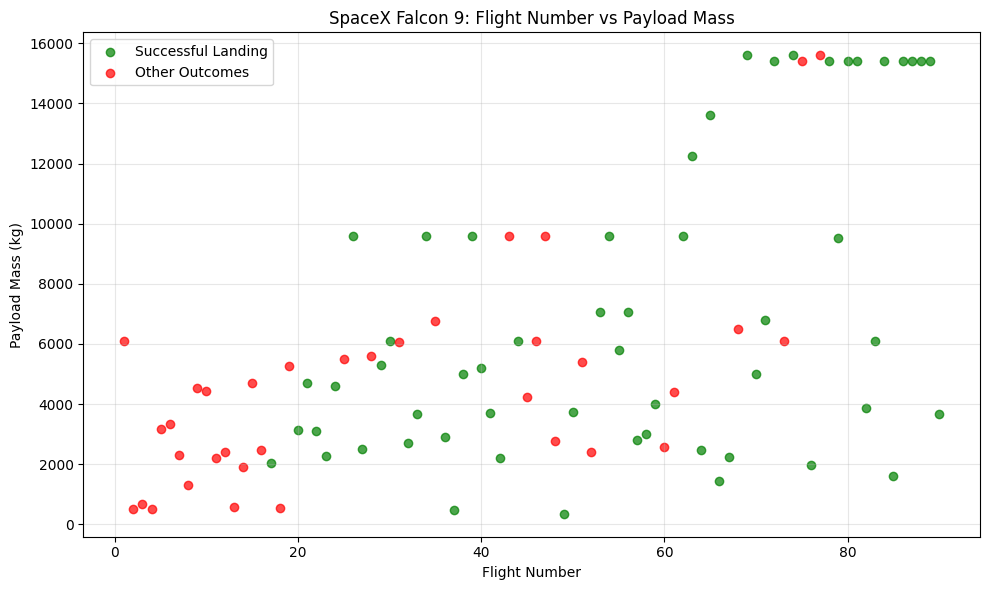

In [8]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Plot successful and other landing outcomes
for landing_class, label, color in [
    (1, "Successful Landing", "green"),
    (0, "Other Outcomes", "red")
]:
    subset = df[df["Class"] == landing_class]

    plt.scatter(
        subset["FlightNumber"],
        subset["PayloadMass"],
        label=label,
        color=color,
        alpha=0.7
    )

plt.title("SpaceX Falcon 9: Flight Number vs Payload Mass")
plt.xlabel("Flight Number")
plt.ylabel("Payload Mass (kg)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("SpaceX_Payload_Scatter.png", dpi=300)
plt.show()


Yearly landing success rates:
Year
2010     0.00
2012     0.00
2013     0.00
2014     0.00
2015    16.67
2016    62.50
2017    77.78
2018    55.56
2019    90.00
2020    84.21
Name: Class, dtype: float64


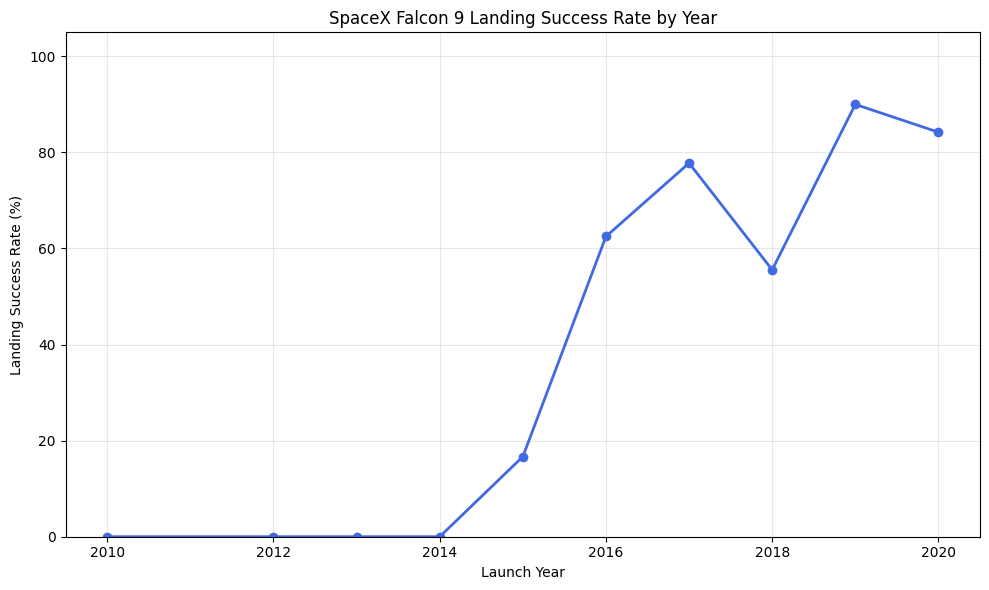

In [9]:

import pandas as pd
import matplotlib.pyplot as plt

# Convert launch dates into years
df["Date"] = pd.to_datetime(df["Date"])
df["Year"] = df["Date"].dt.year

# Calculate yearly landing success rates
yearly_success = df.groupby("Year")["Class"].mean() * 100

print("Yearly landing success rates:")
print(yearly_success.round(2))

# Create the line chart
plt.figure(figsize=(10, 6))

plt.plot(
    yearly_success.index,
    yearly_success.values,
    marker="o",
    linewidth=2,
    color="royalblue"
)

plt.title("SpaceX Falcon 9 Landing Success Rate by Year")
plt.xlabel("Launch Year")
plt.ylabel("Landing Success Rate (%)")
plt.ylim(0, 105)
plt.grid(alpha=0.3)
plt.tight_layout()

# Save the chart
plt.savefig("SpaceX_Yearly_Success.png", dpi=300)
plt.show()


In [10]:

import sqlite3
import pandas as pd

# Connect to a SQLite database
conn = sqlite3.connect("SpaceX_SQL.db")

# Load cleaned SpaceX data into SQL
df.to_sql(
    "SPACEX",
    conn,
    if_exists="replace",
    index=False
)

# Query 1: Count total launches
query1 = """
SELECT COUNT(*) AS TotalLaunches
FROM SPACEX;
"""

print("TOTAL LAUNCHES")
display(pd.read_sql_query(query1, conn))

# Query 2: Launches by site
query2 = """
SELECT LaunchSite, COUNT(*) AS TotalLaunches
FROM SPACEX
GROUP BY LaunchSite
ORDER BY TotalLaunches DESC;
"""

print("LAUNCHES BY SITE")
display(pd.read_sql_query(query2, conn))

# Query 3: Landing success by site
query3 = """
SELECT
    LaunchSite,
    COUNT(*) AS TotalLaunches,
    SUM(Class) AS SuccessfulLandings,
    ROUND(AVG(Class) * 100, 2) AS SuccessRate
FROM SPACEX
GROUP BY LaunchSite
ORDER BY SuccessRate DESC;
"""

print("LANDING SUCCESS BY SITE")
display(pd.read_sql_query(query3, conn))


TOTAL LAUNCHES


,TotalLaunches
0,90


LAUNCHES BY SITE


,LaunchSite,TotalLaunches
0,CCAFS SLC 40,55
1,KSC LC 39A,22
2,VAFB SLC 4E,13


LANDING SUCCESS BY SITE


,LaunchSite,TotalLaunches,SuccessfulLandings,SuccessRate
0,KSC LC 39A,22,17,77.27
1,VAFB SLC 4E,13,9,69.23
2,CCAFS SLC 40,55,29,52.73


In [11]:

# Query 4: Average payload mass by orbit
query4 = """
SELECT Orbit,
       COUNT(*) AS TotalLaunches,
       ROUND(AVG(PayloadMass), 2) AS AvgPayloadMass
FROM SPACEX
GROUP BY Orbit
ORDER BY AvgPayloadMass DESC;
"""

print("PAYLOAD ANALYSIS BY ORBIT")
display(pd.read_sql_query(query4, conn))


# Query 5: Launch site rankings
query5 = """
SELECT LaunchSite,
       COUNT(*) AS TotalLaunches,
       SUM(Class) AS SuccessfulLandings
FROM SPACEX
GROUP BY LaunchSite
ORDER BY SuccessfulLandings DESC;
"""

print("LAUNCH SITE RANKINGS")
display(pd.read_sql_query(query5, conn))


# Query 6: Landing success by year
query6 = """
SELECT
    SUBSTR(Date, 1, 4) AS LaunchYear,
    COUNT(*) AS TotalLaunches,
    SUM(Class) AS SuccessfulLandings,
    ROUND(AVG(Class) * 100, 2) AS SuccessRate
FROM SPACEX
GROUP BY SUBSTR(Date, 1, 4)
ORDER BY LaunchYear;
"""

print("YEARLY LANDING SUCCESS")
display(pd.read_sql_query(query6, conn))


PAYLOAD ANALYSIS BY ORBIT


,Orbit,TotalLaunches,AvgPayloadMass
0,VLEO,14,15315.71
1,PO,9,7583.67
2,SO,1,6104.96
3,GEO,1,6104.96
4,GTO,27,5011.99
5,MEO,3,3987.00
6,LEO,7,3882.84
7,ISS,21,3279.94
8,SSO,5,2060.00
9,ES-L1,1,570.00


LAUNCH SITE RANKINGS


,LaunchSite,TotalLaunches,SuccessfulLandings
0,CCAFS SLC 40,55,29
1,KSC LC 39A,22,17
2,VAFB SLC 4E,13,9


YEARLY LANDING SUCCESS


,LaunchYear,TotalLaunches,SuccessfulLandings,SuccessRate
0,2010,1,0,0.00
1,2012,1,0,0.00
2,2013,3,0,0.00
3,2014,6,0,0.00
4,2015,6,1,16.67
5,2016,8,5,62.50
6,2017,18,14,77.78
7,2018,18,10,55.56
8,2019,10,9,90.00
9,2020,19,16,84.21


In [12]:

import folium
import pandas as pd

# Get unique launch sites and coordinates
sites = df[
    ["LaunchSite", "Latitude", "Longitude"]
].drop_duplicates()

# Create an interactive map
spacex_map = folium.Map(
    location=[35, -100],
    zoom_start=4
)

# Add launch site markers
for _, site in sites.iterrows():
    folium.Marker(
        location=[
            site["Latitude"],
            site["Longitude"]
        ],
        popup=site["LaunchSite"],
        tooltip=site["LaunchSite"],
        icon=folium.Icon(
            color="blue",
            icon="info-sign"
        )
    ).add_to(spacex_map)

# Save interactive map
spacex_map.save("SpaceX_Launch_Sites_Map.html")

# Display map
display(spacex_map)


In [13]:

import folium

# Create map using CartoDB tiles
spacex_map = folium.Map(
    location=[35, -100],
    zoom_start=4,
    tiles="CartoDB positron"
)

# Add launch site markers
sites = df[
    ["LaunchSite", "Latitude", "Longitude"]
].drop_duplicates()

for _, site in sites.iterrows():
    folium.Marker(
        location=[site["Latitude"], site["Longitude"]],
        popup=site["LaunchSite"],
        tooltip=site["LaunchSite"],
        icon=folium.Icon(color="blue")
    ).add_to(spacex_map)

# Save the map
spacex_map.save("SpaceX_Launch_Sites_Map.html")

# Display map
display(spacex_map)


/usr/local/lib/python3.13/dist-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


In [15]:

import folium

# Create map without external tiles
spacex_map = folium.Map(
    location=[35, -100],
    zoom_start=4,
    tiles=None
)

# Add launch site markers
sites = df[
    ["LaunchSite", "Latitude", "Longitude"]
].drop_duplicates()

for _, site in sites.iterrows():
    folium.CircleMarker(
        location=[
            site["Latitude"],
            site["Longitude"]
        ],
        radius=10,
        popup=site["LaunchSite"],
        tooltip=site["LaunchSite"],
        color="blue",
        fill=True,
        fill_color="blue",
        fill_opacity=0.7
    ).add_to(spacex_map)

# Save map
spacex_map.save("SpaceX_Launch_Sites_Map.html")

# Display map
display(spacex_map)


In [16]:

!pip -q install dash plotly


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 28.6 MB/s eta 0:00:00


In [17]:

from dash import Dash, dcc, html, Input, Output
import plotly.express as px

# Create dashboard
app = Dash(__name__)

app.layout = html.Div([
    html.H1("SpaceX Falcon 9 Landing Dashboard"),

    html.H3("Select a Launch Site"),

    dcc.Dropdown(
        id="site-dropdown",
        options=[
            {"label": "All Sites", "value": "ALL"}
        ] + [
            {"label": site, "value": site}
            for site in sorted(df["LaunchSite"].unique())
        ],
        value="ALL",
        clearable=False
    ),

    dcc.Graph(id="landing-chart")
])

@app.callback(
    Output("landing-chart", "figure"),
    Input("site-dropdown", "value")
)
def update_chart(selected_site):
    filtered = (
        df if selected_site == "ALL"
        else df[df["LaunchSite"] == selected_site]
    )

    counts = filtered["Class"].value_counts().reindex(
        [0, 1], fill_value=0
    )

    chart_data = counts.rename_axis(
        "Class"
    ).reset_index(name="Launches")

    chart_data["Outcome"] = chart_data["Class"].map({
        0: "Other Outcomes",
        1: "Successful Landing"
    })

    fig = px.bar(
        chart_data,
        x="Outcome",
        y="Launches",
        color="Outcome",
        title="SpaceX Landing Outcomes"
    )

    return fig

app.run(jupyter_mode="inline", debug=False, port=8050)


<IPython.core.display.Javascript object>